# LabOne Q — Lecture 1: Basic Concepts

This notebook introduces the core building blocks of LabOne Q, following the structure of the
[LabOne Q User Manual](https://docs.zhinst.com/labone_q_user_manual/core/index.html):

1. **Device Setup** — the Descriptor, and Logical Signal Lines
2. **Session** — connecting to (or emulating) the instruments
3. **Calibration** — telling LabOne Q about oscillators, ranges, local oscillators
4. **Sections, Pulses, Sweeps and Averaging** — building an experiment, then visualizing it with the
   Pulse Sheet Viewer and the Output Simulator
5. **Advanced sweeps** — sweeping a custom pulse shape, and sweeping between different pulses using
   `match` / `case`

Everything below runs in **emulation mode** (`do_emulation=True`), so it can be executed without
being connected to real hardware.


## 1. Device Setup and the Descriptor

A LabOne Q experiment always starts from a `DeviceSetup`: a description of which instruments exist,
how they are connected to the physical qubits, and how those connections map to *logical signal
lines*.

The easiest way to build a `DeviceSetup` is from a **Descriptor** — a YAML string (or file) with two
main sections:

- `instruments`: the physical instruments in the setup (HDAWG, SHFSG, SHFQA, SHFQC, PQSC, ...) and
  their addresses/serials.
- `connections`: for each instrument, which of its physical ports are wired to which **logical
  signal**, grouped by qubit.

### Logical signal lines

A *logical signal line* is the abstraction LabOne Q uses so that the rest of your experiment code
never has to talk about physical ports, only "the drive line of qubit 0", or "the acquire line of
qubit 0". Signal lines are grouped into **Logical Signal Groups** (one per qubit, by convention:
`q0`, `q1`, ...), and each line has a **signal type**:

| Signal type      | Typical use                                   | Ports                 |
|-------------------|-----------------------------------------------|------------------------|
| `iq_signal`       | IQ-modulated drive or readout line            | 2 ports (I and Q)      |
| `rf_signal`       | Single-ended line, e.g. a flux line           | 1 port                 |
| `acquire_signal`  | Digitizer input used to acquire results       | 1 input port           |

The picture below shows this for a single qubit: the instruments wire up to logical signal lines
(grouped under `q0`), and everything above the Descriptor — sections, pulses, calibration — only
ever refers to those logical names, never to the underlying physical ports directly.


![Logical signal lines connected to a qubit](attachment:logical_signal_lines.png)


Below we build a minimal single-qubit setup: an SHFSG drives the qubit, an SHFQA reads it out,
and a PQSC provides the reference clock / triggers — a very common instrument combination for
superconducting-qubit setups.

Note: the manual's own examples sometimes use the older `instrument_list` key. That key still works
but raises a `FutureWarning` — new setups should use `instruments`, which is what we use here.


In [ ]:
from laboneq.simple import *
import numpy as np
import matplotlib.pyplot as plt

descriptor = """
instruments:
  SHFSG:
  - address: DEV12123
    uid: device_shfsg
  SHFQA:
  - address: DEV12124
    uid: device_shfqa
  PQSC:
  - address: DEV10123
    uid: device_pqsc
connections:
  device_shfsg:
    - iq_signal: q0/drive_line
      ports: SGCHANNELS/0/OUTPUT
    - iq_signal: q0/drive_line_ef
      ports: SGCHANNELS/0/OUTPUT
  device_shfqa:
    - iq_signal: q0/measure_line
      ports: QACHANNELS/0/OUTPUT
    - acquire_signal: q0/acquire_line
      ports: QACHANNELS/0/INPUT
"""

device_setup = DeviceSetup.from_descriptor(
    descriptor,
    server_host="localhost",
    server_port="8004",
    setup_name="lecture1_setup",
)

print("Setup UID:", device_setup.uid)
print("Logical signal groups:", list(device_setup.logical_signal_groups.keys()))
print("Signals in group 'q0':", list(device_setup.logical_signal_groups["q0"].logical_signals.keys()))


In [ ]:
# Each logical signal knows its own physical channel(s) on the instrument
q0_drive = device_setup.logical_signal_groups["q0"].logical_signals["drive_line"]
q0_measure = device_setup.logical_signal_groups["q0"].logical_signals["measure_line"]
q0_acquire = device_setup.logical_signal_groups["q0"].logical_signals["acquire_line"]

print("drive_line   ->", q0_drive.physical_channel)
print("measure_line ->", q0_measure.physical_channel)
print("acquire_line ->", q0_acquire.physical_channel)


## 2. Session

The `Session` is the object that actually talks to the instruments described in the `DeviceSetup`
(via a LabOne data server). It is responsible for connecting, compiling experiments for the correct
hardware, running them, and returning results.


In [ ]:
session = Session(device_setup)
session.connect(do_emulation=True)
print("Session connected (emulated):", session.connection_state.emulated)


## 3. Calibration

A `DeviceSetup` describes *connectivity*; **Calibration** describes *how each signal should be
driven or measured* — the physical/RF parameters LabOne Q needs to generate correct waveforms and
correctly demodulate acquired data.

Calibration is attached per logical signal, via a `SignalCalibration` object. The most commonly used
properties are:

| Property             | Meaning                                                        |
|-----------------------|------------------------------------------------------------------|
| `oscillator`          | Digital (or hardware) modulation frequency for this signal      |
| `local_oscillator`    | Analog LO frequency, for setups with up/down-conversion         |
| `range`               | Output (or input) power range of the instrument channel         |
| `port_delay`          | Fixed timing correction for that channel                        |
| `mixer_calibration`   | IQ mixer imbalance correction                                   |
| `threshold`           | State-discrimination threshold, for acquire signals              |

This is often called the **baseline calibration**: it is set once per signal and is reused by every
experiment that plays or measures on that signal (an experiment can still override calibration
locally if needed).


In [ ]:
q0_drive.calibration = SignalCalibration(
    oscillator=Oscillator(frequency=100e6, modulation_type=ModulationType.AUTO),
    local_oscillator=Oscillator(frequency=4e9),
    range=10,
)
q0_measure.calibration = SignalCalibration(
    oscillator=Oscillator(frequency=50e6, modulation_type=ModulationType.AUTO),
    local_oscillator=Oscillator(frequency=6e9),
    range=5,
)
q0_acquire.calibration = SignalCalibration(
    oscillator=Oscillator(frequency=50e6, modulation_type=ModulationType.AUTO),
    local_oscillator=Oscillator(frequency=6e9),
    range=5,
)
print("Calibration set on drive_line, measure_line, acquire_line")


## 4. Sections and Pulses

An `Experiment` is built out of **Sections**. A section is a named block of time that groups
together plays, acquires, and delays, and can be nested inside other sections. Two properties are
used constantly:

- `alignment` — `SectionAlignment.LEFT` (default) packs content against the start of the section;
  `SectionAlignment.RIGHT` packs it against the end. Right-alignment is very common for a qubit
  drive pulse immediately followed by a readout, since it lets the drive pulse "hug" the boundary
  with the next section regardless of its own length.
- `play_after` — chains a section to start only once another named section has finished.

**Pulses** are created from the `pulse_library`, e.g. `pulse_library.gaussian(...)` for a smooth
qubit-drive pulse, or `pulse_library.const(...)` for a flat-top readout pulse or integration weight.


## 5. Sweeping a parameter, and how it interacts with averaging

Most calibration experiments don't play a single pulse — they **sweep** a parameter (an amplitude,
a frequency, a pulse length, ...) over a range of values, and **average** each point over many shots
to beat down noise. In LabOne Q both are just more nesting inside `acquire_loop_rt`:

- `exp.sweep(parameter=...)` opens a sweep over a `SweepParameter` / `LinearSweepParameter`. Anything
  played inside can use that parameter directly, e.g. `exp.play(..., amplitude=my_sweep)`.
- The **averaging loop** (the `count=` of `acquire_loop_rt`) and the **sweep** can be nested in two
  different orders, which changes what "one repeat" means:



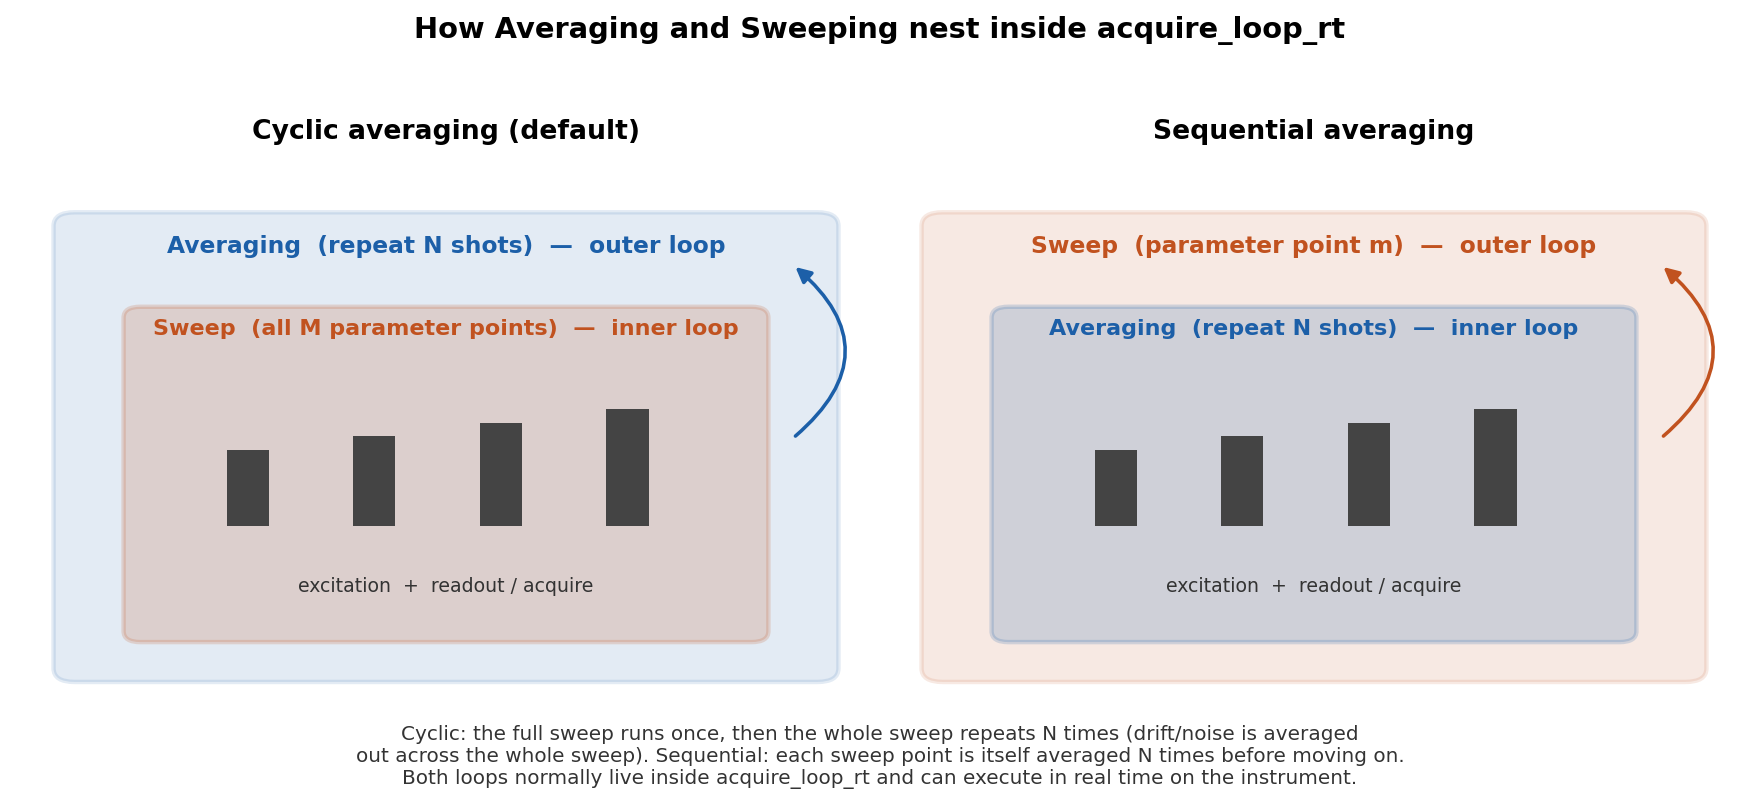


- **Cyclic averaging** (the default, `AveragingMode.CYCLIC`): the sweep is the *inner* loop. The
  entire sweep runs once, then the whole thing repeats `count` times. Because every sweep point is
  revisited on every repeat, slow drifts get averaged out evenly across the whole sweep.
- **Sequential averaging** (`AveragingMode.SEQUENTIAL`): the sweep is the *outer* loop. Each
  parameter point is fully averaged (`count` shots) before moving to the next point.

Both loops normally live inside `acquire_loop_rt` and, when the parameter is used only inside a real
hardware pulse (like an amplitude or a phase), LabOne Q can execute the whole nested loop **in real
time** directly on the instrument — no near-time round-trip per point.

Below we sweep the amplitude of the excitation pulse across 11 values, in a standard **Amplitude
Rabi** experiment, using cyclic averaging (4 shots).


In [ ]:
readout_pulse = pulse_library.const(uid="readout_pulse", length=400e-9, amplitude=1.0)
readout_weight = pulse_library.const(uid="readout_weight", length=400e-9, amplitude=1.0)
x90 = pulse_library.gaussian(uid="x90", length=100e-9, amplitude=1.0)

amp_sweep = LinearSweepParameter(uid="amp", start=0.1, stop=1.0, count=11)
shot_repetition_time = 2000e-9

exp = Experiment(
    uid="Amplitude Rabi",
    signals=[
        ExperimentSignal("drive"),
        ExperimentSignal("measure"),
        ExperimentSignal("acquire"),
    ],
)

with exp.acquire_loop_rt(
    uid="shots",
    count=4,
    averaging_mode=AveragingMode.CYCLIC,
    acquisition_type=AcquisitionType.INTEGRATION,
    repetition_mode=RepetitionMode.CONSTANT,
    repetition_time=shot_repetition_time,
):
    with exp.sweep(parameter=amp_sweep):
        with exp.section(uid="excitation", alignment=SectionAlignment.RIGHT):
            exp.play(signal="drive", pulse=x90, amplitude=amp_sweep)
        with exp.section(uid="readout", play_after="excitation"):
            exp.play(signal="measure", pulse=readout_pulse)
            exp.acquire(signal="acquire", handle="rabi", kernel=readout_weight)

exp.set_signal_map({
    "drive": "/logical_signal_groups/q0/drive_line",
    "measure": "/logical_signal_groups/q0/measure_line",
    "acquire": "/logical_signal_groups/q0/acquire_line",
})

compiled_exp = session.compile(exp)
print("Compiled OK")


In [ ]:
result = session.run(compiled_exp)

In [ ]:
from laboneq.contrib.example_helpers.plotting.plot_helpers import plot_results

result.acquired_results["rabi"].data

### The Pulse Sheet Viewer

`show_pulse_sheet` renders the compiled experiment as an interactive, zoomable HTML timeline — every
section, pulse, and acquire event on every signal line, laid out in time. It is the fastest way to
sanity-check that an experiment's *timing and structure* are what you intended, before ever touching
real hardware.


In [ ]:
from laboneq.contrib.example_helpers.plotting.plot_helpers import plot_simulation

plot_simulation(compiled_exp, length=500e-9)

In [ ]:
show_pulse_sheet("lecture1_amplitude_rabi", compiled_exp)


### Simulating the output signals

`show_pulse_sheet` shows structure; `plot_simulation` shows the actual **simulated waveforms** that
would be sent to the instruments — amplitude and phase, sample by sample, exactly as compiled. It is
built on top of LabOne Q's `OutputSimulator`, which reconstructs true output waveforms from the
compiled experiment without needing any hardware.


In [ ]:
from laboneq.contrib.example_helpers.plotting.plot_helpers import plot_simulation

plot_simulation(
    compiled_exp,
    start_time=0,
    length=6e-6,
    plot_width=10,
    plot_height=2.5,
)


## 6. Overlaying every Rabi drive pulse with the Output Simulator

`plot_simulation` is great for looking at an experiment as it plays out over time. But to *see* an
amplitude Rabi sweep at a glance, it's often more instructive to overlay every drive pulse on the
same time axis, aligned to its own start — so the growing pulse "envelope" is immediately visible.

We do this directly with `OutputSimulator`:

1. Build an `OutputSimulator` from the compiled experiment.
2. Get the physical channel that corresponds to our drive logical signal.
3. For each sweep step, grab a short waveform *snippet* starting at that step, using
   `get_snippet(channel, start=..., output_length=...)`. Because we set
   `repetition_mode=RepetitionMode.CONSTANT`, every shot has the same fixed duration
   (`shot_repetition_time`), so step `i`'s pulse always starts at `t = i * shot_repetition_time`.
4. Plot every snippet on the same relative time axis.


In [ ]:
from laboneq.simulator.output_simulator import OutputSimulator

sim = OutputSimulator(compiled_exp)
drive_port = device_setup.logical_signal_by_uid("q0/drive_line").physical_channel

plt.figure(figsize=(8, 4))
for step in range(amp_sweep.count):
    start = shot_repetition_time * step
    snippet = sim.get_snippet(drive_port, start=start, output_length=120e-9)
    plt.plot((snippet.time - start) * 1e9, snippet.wave.real, label=f"amp={amp_sweep.values[step]:.2f}")

plt.xlabel("Time within pulse (ns)")
plt.ylabel("Drive amplitude (a.u.)")
plt.title("Amplitude Rabi: all drive pulses overlaid")
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


Each curve is one step of the amplitude sweep, all aligned to the same starting time. The
Gaussian envelope grows steadily from `amp=0.10` to `amp=1.00`, exactly matching `amp_sweep` — this
is the real, compiled hardware sweep (`exp.sweep(...)` inside `acquire_loop_rt`), not a Python-side
reconstruction.


## 7. A more advanced sweep: a custom pulse shape via `register_pulse_functional`

So far we have only swept a pulse's **amplitude** — the pulse *shape* stayed the same, only its
scale changed. `pulse_library.register_pulse_functional` lets us go further and define our own
pulse *shapes* as plain Python/NumPy functions.

The sampler function receives `x`, a vector ranging from `-1` to `+1` across the pulse, plus any
extra keyword arguments passed in via `pulse_parameters`. It must return the (unit-amplitude,
unit-length) envelope; LabOne Q takes care of rescaling it to the pulse's actual `length` and
`amplitude`.

Below we define a **square pulse with a linear ramp-up**, where the ramp-up time is expressed as
`ramp_up_ratio` — the *fraction* of the total pulse length used for the ramp (e.g. `0.1` means the
first 10% of the pulse ramps linearly from 0 to full amplitude, and the remaining 90% is flat).


In [ ]:
def _square_with_ramp_shape(x, ramp_up_ratio=0.1, **_):
    """Square pulse with a linear ramp-up.

    Args:
        ramp_up_ratio: fraction (0-1) of the total pulse length used for the
            linear ramp from 0 to full amplitude. The rest of the pulse is flat.
    """
    ramp_length = ramp_up_ratio * 2.0  # x spans [-1, 1], i.e. a total length of 2
    y = np.ones(len(x))
    if ramp_length > 0:
        ramp_end = -1 + ramp_length
        in_ramp = x < ramp_end
        y[in_ramp] = np.clip((x[in_ramp] + 1) / ramp_length, 0, 1)
    return y


# register the sampler function as a new pulse type, "square_with_ramp"
square_with_ramp = pulse_library.register_pulse_functional(
    _square_with_ramp_shape, name="square_with_ramp"
)

# quick look at the raw shape itself, for a couple of ramp_up_ratio values
x_axis = np.linspace(-1, 1, 201)
plt.figure(figsize=(6, 3))
for ratio in [0.05, 0.2, 0.5]:
    plt.plot(x_axis, _square_with_ramp_shape(x_axis, ramp_up_ratio=ratio), label=f"ramp_up_ratio={ratio}")
plt.legend(fontsize=8)
plt.title("square_with_ramp(x, ramp_up_ratio)")
plt.tight_layout()
plt.show()


### Sweeping `ramp_up_ratio`

`ramp_up_ratio` changes the *samples* of the pulse itself, not just a hardware amplitude/phase
register — so, unlike the amplitude sweep above, this **cannot** be executed purely in real time.
LabOne Q automatically compiles this as a **near-time sweep**: for each value, it (re)computes the
waveform, uploads it, and plays it, before moving to the next value. This is exactly the same
`exp.sweep(...)` syntax as before — LabOne Q figures out real-time vs. near-time automatically from
how the parameter is used.


In [ ]:
square_pulse = square_with_ramp(uid="square_ramp", length=200e-9, amplitude=1.0)

ramp_sweep = LinearSweepParameter(uid="ramp_up_ratio", start=0.05, stop=0.5, count=5)

exp_ramp = Experiment(uid="Ramp-up sweep", signals=[ExperimentSignal("drive")])

with exp_ramp.sweep(uid="ramp_sweep", parameter=ramp_sweep):
    with exp_ramp.acquire_loop_rt(uid="shots", count=1, acquisition_type=AcquisitionType.INTEGRATION):
        with exp_ramp.section(uid="play"):
            exp_ramp.play(signal="drive", pulse=square_pulse, pulse_parameters={"ramp_up_ratio": ramp_sweep})
            exp_ramp.delay(signal="drive", time=50e-9)

exp_ramp.set_signal_map({"drive": "/logical_signal_groups/q0/drive_line"})
compiled_ramp_exp = session.compile(exp_ramp)
print("Compiled OK (near-time sweep over ramp_up_ratio)")


### Plotting the simulation

Because this is a near-time sweep, each step is compiled and uploaded on its own — a single
`plot_simulation` call only ever shows *one* near-time step's real-time program (the one that was
compiled). To see how the pulse shape changes across the whole sweep, we compile and simulate the
same experiment once per value of `ramp_up_ratio`, and overlay the results — this reflects exactly
what happens on the instrument, one near-time step at a time.


In [ ]:
drive_port = device_setup.logical_signal_by_uid("q0/drive_line").physical_channel

plt.figure(figsize=(8, 4))
for ratio in ramp_sweep.values:
    exp_step = Experiment(uid="ramp_step", signals=[ExperimentSignal("drive")])
    with exp_step.acquire_loop_rt(uid="shots", count=1, acquisition_type=AcquisitionType.INTEGRATION):
        with exp_step.section(uid="play"):
            exp_step.play(signal="drive", pulse=square_pulse, pulse_parameters={"ramp_up_ratio": float(ratio)})
    exp_step.set_signal_map({"drive": "/logical_signal_groups/q0/drive_line"})
    compiled_step = session.compile(exp_step)

    sim_step = OutputSimulator(compiled_step)
    snippet = sim_step.get_snippet(drive_port, start=0, output_length=250e-9)
    plt.plot(snippet.time * 1e9, snippet.wave.real, label=f"ramp_up_ratio={ratio:.2f}")

plt.xlabel("Time (ns)")
plt.ylabel("Drive amplitude (a.u.)")
plt.title("square_with_ramp: simulated output for each near-time sweep step")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


Each curve is the *actual simulated hardware waveform* LabOne Q would upload for that near-time
step — the ramp visibly gets longer and shallower as `ramp_up_ratio` grows from `0.05` to `0.5`,
while the flat-top portion of the 200 ns pulse shrinks accordingly.


## 8. Sweeping between different pulses with `match` / `case`

A regular sweep changes a *number* (an amplitude, a ratio, ...). Sometimes you want to sweep between
entirely different **pulses**, or even different **sequences of operations** — e.g. comparing a
square pulse, a Gaussian pulse, and a sawtooth ramp in the same real-time sweep. Python's `amplitude=
sweep_param` mechanism can't express "play a different pulse object", so LabOne Q provides a
dedicated construct for this: `exp.match(sweep_parameter=...)` together with `exp.case(state=...)`.

```python
with exp.sweep(parameter=p):
    with exp.match(sweep_parameter=p):
        with exp.case(state=0):
            exp.play(signal, pulse_a)
        with exp.case(state=1):
            exp.play(signal, pulse_b)
```

Unlike the `ramp_up_ratio` sweep above, every branch here is a *complete, pre-compiled waveform* —
LabOne Q only has to pick which one to play, which a real AWG command table can do in real time. So
this whole construct **stays a real-time sweep**, even though it selects between structurally
different pulses.


In [ ]:
pulse_const = pulse_library.const(uid="p_const", length=100e-9, amplitude=1.0)
pulse_gauss = pulse_library.gaussian(uid="p_gauss", length=100e-9, amplitude=1.0)
pulse_saw = pulse_library.sawtooth(uid="p_saw", length=100e-9, amplitude=1.0)

pulse_type_sweep = LinearSweepParameter(uid="pulse_type", start=0, stop=2, count=3)

exp_match = Experiment(uid="Match-case pulse sweep", signals=[ExperimentSignal("drive")])

with exp_match.acquire_loop_rt(uid="shots", count=1, acquisition_type=AcquisitionType.INTEGRATION):
    with exp_match.sweep(uid="pulse_type_sweep", parameter=pulse_type_sweep):
        with exp_match.section(uid="pre_delay"):
            exp_match.delay(signal="drive", time=20e-9)
        with exp_match.match(sweep_parameter=pulse_type_sweep):
            with exp_match.case(state=0):
                exp_match.play(signal="drive", pulse=pulse_const)
            with exp_match.case(state=1):
                exp_match.play(signal="drive", pulse=pulse_gauss)
            with exp_match.case(state=2):
                exp_match.play(signal="drive", pulse=pulse_saw)
        with exp_match.section(uid="post_delay"):
            exp_match.delay(signal="drive", time=20e-9)

exp_match.set_signal_map({"drive": "/logical_signal_groups/q0/drive_line"})
compiled_match_exp = session.compile(exp_match)
print("Compiled OK (real-time sweep, selecting between 3 different pulses)")


In [ ]:
plot_simulation(
    compiled_match_exp,
    start_time=0,
    length=6e-7,
    signals=["drive"],
    plot_width=10,
    plot_height=2.5,
)
